Let's implement a function that turns a list of numbers into a bar chart.

In the end, you should be able to call it like this:

```
bar_chart([0.5, 1.0, 0.9, 1.0, 1.5, 0.1], 200, 100)
```

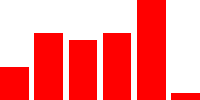

### A Single Bar
A bar chart consists of bars that are placed next to each other.
To determine the height of a bar, we need to take into account:

* the amount of space we have for the complete chart (specifically, the `chart_height`)
* the value represented by this specific bar (`value`)
* the maximum value to be shown in the chart (`max_value`), which will be represented by the tallest bar, which will take up the entire `chart_height`

Compute the `bar_height`, and then construct a <API>rectangle</API> with the necessary dimensions and <API>red</API> color.

In [ ]:
from pytamaro import Graphic, rectangle, red, show_graphic

def bar(bar_width: float, value: float, max_value: float, chart_height: float) -> Graphic:
    bar_height = # TODO
    return # TODO

# Show a bar with a width of 60, that would fits into a chart with an overall height of 200, 
# and that represents the value of 5.5 out of 10.0.
show_graphic(bar(60, 5.5, 10.0, 200))

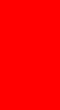

In [17]:
#teacher-only
from pytamaro import Graphic, rectangle, red, show_graphic

def bar(bar_width: float, value: float, max_value: float, chart_height: float) -> Graphic:
    bar_height = value / max_value * chart_height
    return rectangle(bar_width, bar_height, red)

# Show a bar with a width of 60, that would fits into a chart with an overall height of 200, 
# and that represents the value of 5.5 out of 10.0.
show_graphic(bar(60, 5.5, 10.0, 200))

### A Gap

We will want gaps between bars. To construct a gap of a specific width, we can create a rectangle with that width and with a height of 0. While we have to specify the color of the rectangle, the color we pick does not really matter, because the rectangle has 0 height and thus is invisible.

In [20]:
def gap(gap_width: float) -> Graphic:
    return # TODO

# This gap will not be visible; and it cannot be shown on its own.
show_graphic(gap(100))

Cannot show/save a graphic of size 100x0 as it has no area


In [ ]:
#teacher-only
def gap(gap_width: float) -> Graphic:
    return rectangle(gap_width, 0, red)

# This gap will not be visible; and cannot be shown on its own.
show_graphic(gap(100))

Let's "show" the gap by creating two 60-width bars separated by a 10-width gap:

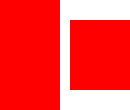

In [24]:
from pytamaro import beside

show_graphic(
    beside(
        bar(60, 5.5, 10.0, 200),
        beside(
            gap(10),
            bar(60, 3.5, 10.0, 200)
        )
    )
)

Do you see how they are separated? That's our gap!

Also, do you realize that they are vertically centered? We don't want that for our bar chart: we will want the bars to be bottom-aligned. Thus, we won't use <API>beside</API> to compose them.

### A Complete Bar Chart

Given the `bar` and `gap` functions, we are now ready to create a complete bar chart.

Our `bar_chart` function receives a list of values, and the desired overall width and height of the chart.
Given this information, compute:

* `max_value` - the maximum of the given values
* `bar_count` - the number of bars
* `gap_count` - the number of gaps between bars
* `bar_width` - the width of one bar (given `width`, `bar_count`, `gap_count`, and `gap_width_fraction`)
* `gap_width` - given `bar_width` and `gap_width_fraction`

Given all this information, implement a loop that uses `bar`, `gap`, <API>empty_graphic</API>, <API>compose</API>, and <API>pin</API> to combine the necessary bars and gaps. Make sure that the gaps only exist between bars (the bars extend all the way to the left and right edge of the chart).

In [ ]:
from pytamaro import empty_graphic, compose, pin, bottom_left, bottom_right

def bar_chart(values: list[float], width: float, height: float) -> Graphic:
    gap_width_fraction = 0.2 # gap width as fraction of bar width
    max_value = # TODO
    bar_count = # TODO
    gap_count = # TODO
    bar_width = # TODO
    gap_width = # TODO
    result = # TODO
    # TODO loop
    return result

show_graphic(bar_chart([0.5, 1.0, 0.9, 1.0, 1.5, 0.1], 200, 100))

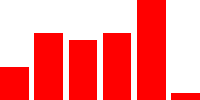

In [28]:
#teacher-only
from pytamaro import empty_graphic, compose, pin, bottom_left, bottom_right, save_graphic

def bar_chart(values: list[float], width: float, height: float) -> Graphic:
    gap_width_fraction = 0.2 # gap width as fraction of bar width
    max_value = max(values)
    bar_count = len(values)
    gap_count = bar_count - 1
    bar_width = width / (bar_count + gap_width_fraction * gap_count)
    gap_width = 0.2 * bar_width
    result = empty_graphic()
    for i, value in enumerate(values):
        b = bar(bar_width, value, max_value, height)
        result = compose(pin(bottom_right, result), pin(bottom_left, b))
        if (i < bar_count - 1):
            g = rectangle(gap_width, 0, red)
            result = compose(pin(bottom_right, result), pin(bottom_left, g))
    return result

show_graphic(bar_chart([0.5, 1.0, 0.9, 1.0, 1.5, 0.1], 200, 100))
save_graphic("bar-chart.svg", bar_chart([0.5, 1.0, 0.9, 1.0, 1.5, 0.1], 200, 200))
